In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import torch
import general

In [6]:
import general
import importlib

importlib.reload(general)

print(dir(general))

['GradientBoostingClassifier', 'KNeighborsClassifier', 'MLPClassifier', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'accuracy_score', 'best_decision_tree_hyperparameters', 'best_gradient_boosting_hyperparameters', 'best_k', 'best_mlp_hyperparameters', 'best_random_forest_hyperparameters', 'best_svm_kernel_C', 'confusion_matrix', 'decision_tree_model', 'evaluate_models', 'f1_score', 'gradient_boosting_model', 'knn_model', 'logistic_regression_model', 'math', 'mlp_model', 'pd', 'plot_confusion_matrices', 'plt', 'precision_score', 'random_forest_model', 'recall_score', 'sns', 'svm_model']


Data Loading

In [7]:
import pandas as pd

df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")

print(df.head())

   Diabetes_binary  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0              0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1              0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2              0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3              0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4              0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      18.0      15.0       1.0  0.0   9.0   

In [8]:
X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"]
print(X.columns.tolist())
print("Nombre de features :", X.shape[1])
print(y.name)

['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Nombre de features : 21
Diabetes_binary


Exploratory Data Analysis

In [5]:
print(df.shape)
print(df.head())

(253680, 22)
   Diabetes_binary  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0              0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1              0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2              0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3              0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4              0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      18.0      15.0       1.0 

In [6]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [7]:
print(df.describe())

       Diabetes_binary         HighBP       HighChol      CholCheck  \
count    253680.000000  253680.000000  253680.000000  253680.000000   
mean          0.139333       0.429001       0.424121       0.962670   
std           0.346294       0.494934       0.494210       0.189571   
min           0.000000       0.000000       0.000000       0.000000   
25%           0.000000       0.000000       0.000000       1.000000   
50%           0.000000       0.000000       0.000000       1.000000   
75%           0.000000       1.000000       1.000000       1.000000   
max           1.000000       1.000000       1.000000       1.000000   

                 BMI         Smoker         Stroke  HeartDiseaseorAttack  \
count  253680.000000  253680.000000  253680.000000         253680.000000   
mean       28.382364       0.443169       0.040571              0.094186   
std         6.608694       0.496761       0.197294              0.292087   
min        12.000000       0.000000       0.000000      

In [8]:
print(df.isnull().sum()) #verify if there are any missing values in the dataset

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


In [18]:
#verification of repeated rows
print(df.duplicated().sum())

24206


Clean dataset by removing duplicates

In [19]:
#Clean the dataset by removing duplicates
df=df.drop_duplicates()
print(df.duplicated().sum())
print(df.shape)

0
(229474, 22)


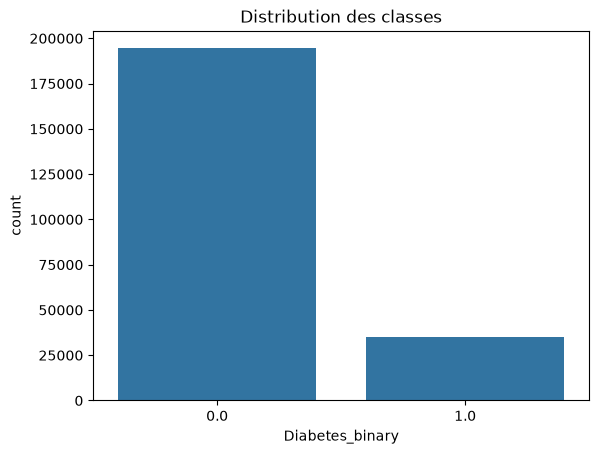

Diabetes_binary
0.0    194377
1.0     35097
Name: count, dtype: int64
Diabetes_binary
0.0    84.705457
1.0    15.294543
Name: proportion, dtype: float64


In [20]:
#class distribution
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Diabetes_binary', data=df)
plt.title("Distribution des classes")
plt.show()

print(df['Diabetes_binary'].value_counts())
print(df['Diabetes_binary'].value_counts(normalize=True)*100)

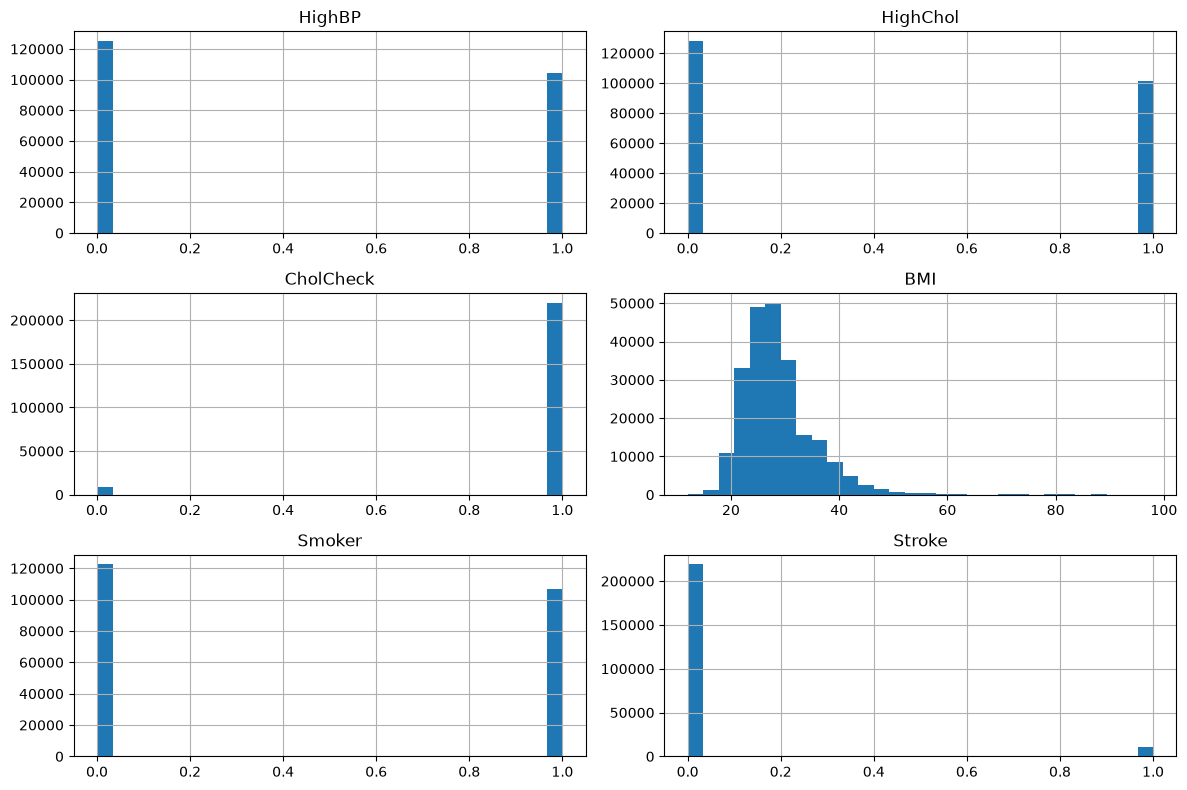

In [21]:
#histogram of some features
features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke"
]

df[features].hist(
    figsize=(12,8),
    bins=30
)

plt.tight_layout()
plt.show()

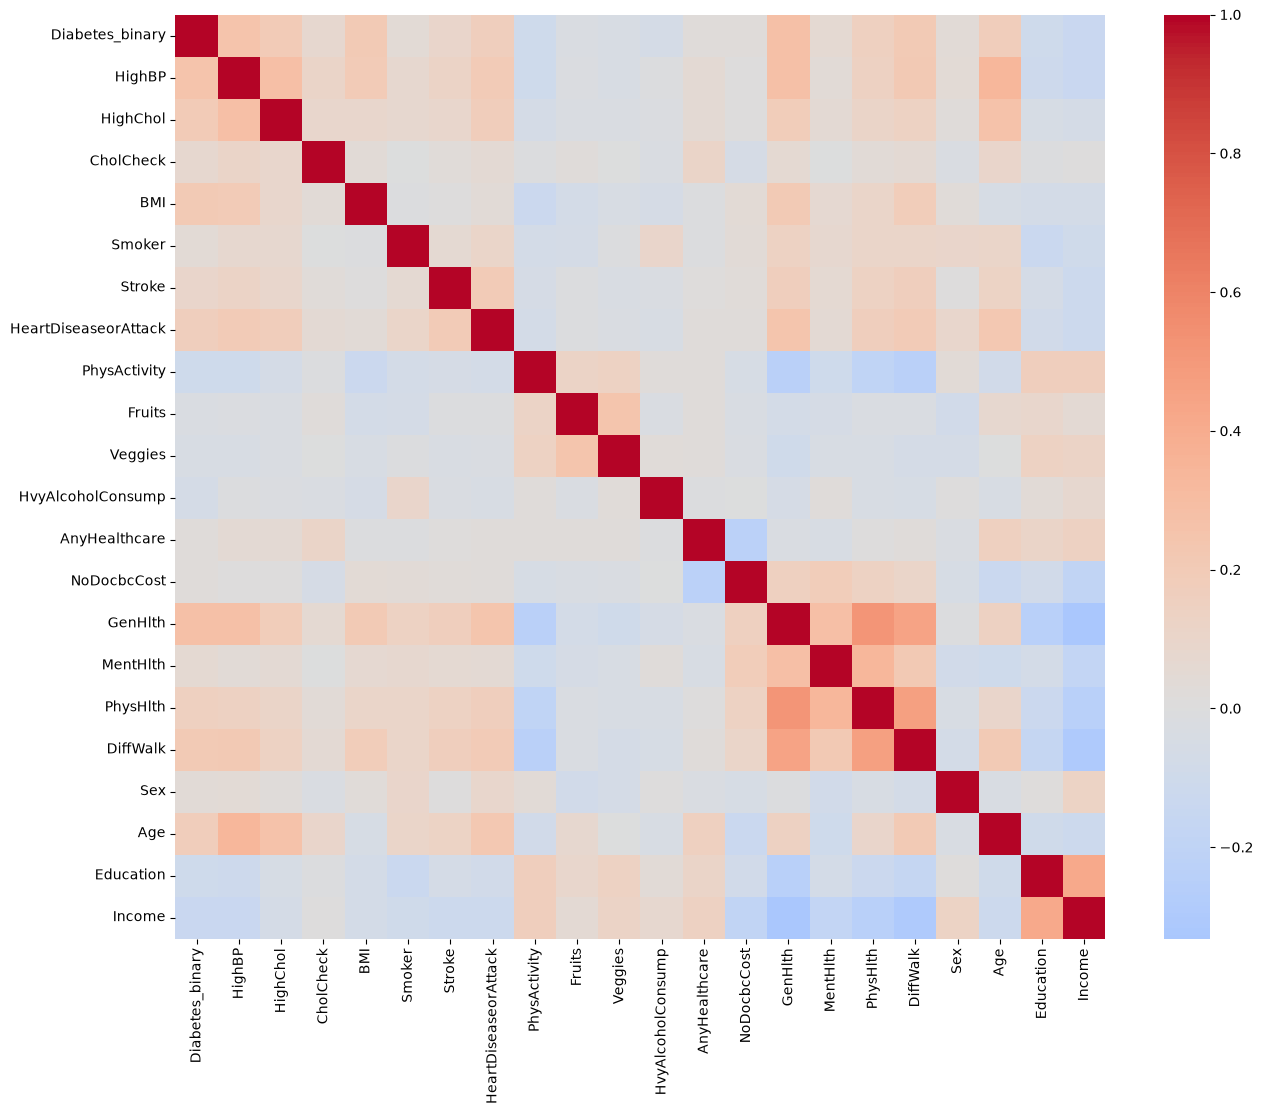

In [24]:
#correlation matrix
corr = df.corr()

plt.figure(figsize=(15,12))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)
plt.show()

In [25]:
#most correlated features for diabetes
corr_diabete = df.corr()['Diabetes_binary']

corr_diabete = corr_diabete.abs().sort_values(ascending=False)

print(corr_diabete.head(15))

Diabetes_binary         1.000000
GenHlth                 0.276940
HighBP                  0.254318
DiffWalk                0.205302
BMI                     0.205086
HighChol                0.194944
Age                     0.177263
HeartDiseaseorAttack    0.168213
PhysHlth                0.156211
Income                  0.140659
Education               0.102686
PhysActivity            0.100404
Stroke                  0.099193
CholCheck               0.072523
HvyAlcoholConsump       0.065950
Name: Diabetes_binary, dtype: float64


These values of correlation of each feature with our diabete indicator proves that some features participate less in deciding weither a person is diabetic or not. This lead us to try the **feature selection** method in order to keep only features necessary for deciding.

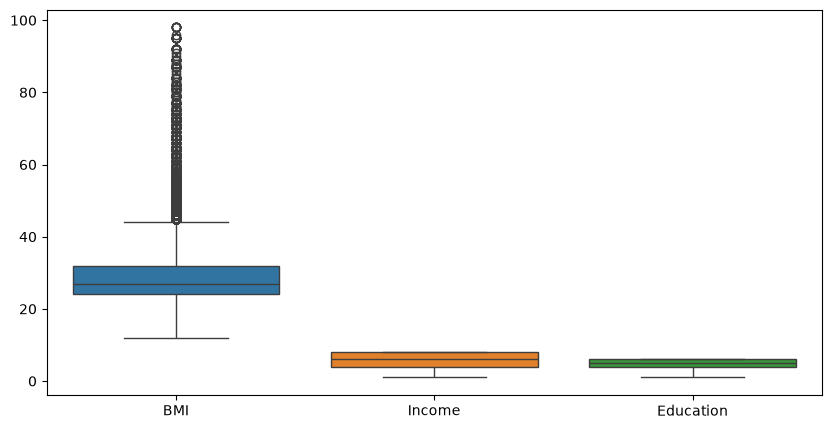

In [26]:
#visualization of outliers
plt.figure(figsize=(10,5))

sns.boxplot(data=df[['BMI',
                     'Income',
                     'Education']])

plt.show()

_**Why PCA won't be Used here ?**_

Principal Component Analysis (PCA) was not retained as a preprocessing step for the Diabetes BRFSS dataset. Unlike high-dimensional datasets, this dataset contains a relatively small number of features, many of which are binary health indicators (e.g., HighBP, Smoker, Stroke, HeartDiseaseorAttack). PCA is primarily designed for continuous variables and aims to maximize the explained variance rather than the predictive power of the features.

Furthermore, PCA transforms the original variables into combinations of principal components, which reduces interpretability. Since the objective of this study is not only to achieve good predictive performance but also to identify important health-related factors associated with diabetes, preserving the original features is preferable. **Feature selection** was therefore chosen instead of PCA, as it reduces dimensionality while maintaining the interpretability of the selected predictors.

# **Data Manipulation**

**Data split**

In [9]:
# Split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

**Feature Selection (Mutual Information)**

Feature selection is a dimensionality reduction technique that aims to identify and retain only the most relevant features for a predictive task. By removing redundant, irrelevant, or less informative variables, feature selection can reduce model complexity, improve computational efficiency, and potentially enhance predictive performance. Unlike Principal Component Analysis (PCA), feature selection preserves the original meaning and interpretability of the variables. In this study, feature selection was applied to retain the most informative health indicators related to diabetes while reducing the dimensionality of the dataset.

In [14]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
selector = SelectKBest(score_func=mutual_info_classif,k=10)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)
X_val_selected = selector.transform(X_val_scaled)
# Display selected features
selected_features = X.columns[selector.get_support()]

print("\nSelected Features:")
print(selected_features.tolist())


Selected Features:
['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'PhysHlth', 'DiffWalk', 'Age', 'Income']


**SMOTE**

SMOTE is an oversampling technique designed to address class imbalance in classification problems. Instead of simply duplicating existing minority class samples, SMOTE generates new synthetic observations by interpolating between neighboring minority instances. This process helps create a more balanced training dataset and reduces the bias of machine learning models toward the majority class. In this study, SMOTE was applied only to the training set after feature selection in order to improve the detection of diabetic patients and evaluate the impact of class balancing on model performance.

In [15]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_selected,
    y_train
)

print("\nClass distribution before SMOTE:")
print(y_train.value_counts())

print("\nClass distribution after SMOTE:")
print(pd.Series(y_train_balanced).value_counts())


Class distribution before SMOTE:
Diabetes_binary
0.0    152834
1.0     24742
Name: count, dtype: int64

Class distribution after SMOTE:
Diabetes_binary
0.0    152834
1.0    152834
Name: count, dtype: int64


# **Classification methods**

**KNN method**

K-Nearest Neighbors (KNN) is a non-parametric classification algorithm that assigns a class to a new observation based on the classes of its nearest neighbors in the feature space. Because KNN relies on distance calculations, feature standardization is essential to ensure that all variables contribute equally to the classification process. The optimal value of $k$, representing the number of neighbors considered, was determined through hyperparameter tuning. The model was evaluated with and without SMOTE to analyze the influence of class imbalance on predictive performance.

In [ ]:
#just strandard scaling and feature selection for knn
best_k_selected, best_accuracy_selected = general.best_k(X_train_selected, y_train, X_val_selected, y_val, max_k=10)
knn_model_selected, accuracy_selected=general.knn_model(X_train_balanced, y_train_balanced, X_test_selected, y_test, best_k_selected)
print(accuracy_selected)
print(f"Best k: {best_k_selected}, Best Accuracy: {best_accuracy_selected}")

0.7511563124145906
Best k: 10, Best Accuracy: 0.8597445600756859


In [16]:
best_k, best_accuracy = general.best_k(X_train_balanced, y_train_balanced, X_val_selected, y_val, max_k=20)
knn_model, accuracy=general.knn_model(X_train_balanced, y_train_balanced, X_test_selected, y_test, best_k)
print(accuracy)
print(f"Best k: {best_k}, Best Accuracy: {best_accuracy}")

0.8170135603910438
Best k: 2, Best Accuracy: 0.8168558814254179


_**Comment**:_ 

The application of SMOTE after standardization and feature selection improved the performance of the KNN classifier. Without SMOTE, the model achieved a test accuracy of 75.12%. After balancing the training set using SMOTE, the accuracy increased to 81.70%. This improvement suggests that the original dataset suffered from class imbalance, which negatively affected the classifier's ability to learn decision boundaries for the minority class. By generating synthetic samples for the minority class, SMOTE provided a more balanced training distribution and enhanced the model's generalization performance

**Logistic Regression**

Logistic Regression is a widely used supervised learning algorithm for binary classification problems. It estimates the probability that an observation belongs to a particular class by applying a logistic function to a linear combination of the input features. Despite its simplicity, Logistic Regression often provides strong baseline performance and offers interpretable model coefficients. In this study, the model was trained on standardized data and evaluated after feature selection and class balancing in order to assess the contribution of each preprocessing step.

In [18]:
#just strandard scaling
lgs_model_standard, accuracy_standard=general.logistic_regression_model(X_train_scaled, y_train, X_test_scaled, y_test)
print(accuracy_standard)

0.8627404604225797


In [19]:
#just strandard+selected_features
lgs_model_selected, accuracy_selected=general.logistic_regression_model(X_train_selected, y_train, X_test_selected, y_test)
print(accuracy_selected)

0.8630032586986229


In [17]:
lgs_model, accuracy=general.logistic_regression_model(X_train_balanced, y_train_balanced, X_test_selected, y_test)
print(accuracy)

0.7305003679175864


_**Comment**:_

For Logistic Regression, feature selection had almost no impact on predictive performance, with the accuracy remaining stable around 86.3%. This indicates that the selected features preserved most of the relevant information contained in the original dataset. However, applying SMOTE significantly reduced the test accuracy from 86.30% to 73.05%. This suggests that the synthetic samples generated by SMOTE altered the original data distribution and negatively affected the model's generalization ability. Therefore, for Logistic Regression, standardization combined with feature selection provided the best overall performance.

The impact of SMOTE depends on the classifier. While SMOTE improved the performance of KNN from 75.12% to 81.70%, it substantially degraded the performance of Logistic Regression from 86.30% to 73.05%. This difference can be explained by the nature of the algorithms. KNN is sensitive to local class distributions and may benefit from a more balanced dataset, whereas Logistic Regression already handles moderate class imbalance relatively well and may be negatively affected by synthetic observations.

**Decision tree**

A Decision Tree is a supervised learning algorithm that classifies observations by recursively splitting the data according to feature values. Each split is chosen to maximize the separation between classes, resulting in a tree-like structure that is easy to interpret and visualize. Decision Trees can model non-linear relationships and require minimal preprocessing. In this work, hyperparameters such as the maximum depth and the minimum number of samples required for a split were optimized to control model complexity and reduce overfitting. The model was evaluated using the selected features, both with and without SMOTE.

In [24]:
#Standard+feature selection
best_max_depth_selected, best_min_samples_split_selected, best_accuracy_selected=general.best_decision_tree_hyperparameters(X_train_selected, y_train, X_val_selected, y_val, max_depth_list=[None, 5, 7], min_samples_split_list=[2, 4, 7])
dt_model_selected, accuracy_selected=general.decision_tree_model(X_train_selected, y_train, X_test_selected, y_test, best_max_depth_selected, best_min_samples_split_selected)
print(f"Best max_depth selected: {best_max_depth_selected}, Best min_samples_split selected: {best_min_samples_split_selected}, Best Accuracy selected: {best_accuracy_selected}")
print(f"Decision Tree accuracy selected: {accuracy_selected}")

Best max_depth selected: 7, Best min_samples_split selected: 2, Best Accuracy selected: 0.8632397771470619
Decision Tree accuracy selected: 0.8644223693892568


In [ ]:
#Standard+feature selection +Smote
best_max_depth, best_min_samples_split, best_accuracy=general.best_decision_tree_hyperparameters(X_train_balanced, y_train_balanced, X_val_selected, y_val, max_depth_list=[None, 5, 7], min_samples_split_list=[2, 4, 7])
dt_model, accuracy=general.decision_tree_model(X_train_balanced, y_train_balanced, X_test_selected, y_test, best_max_depth, best_min_samples_split)
print(f"Best max_depth: {best_max_depth}, Best min_samples_split: {best_min_samples_split}, Best Accuracy: {best_accuracy}")
print(f"Decision Tree accuracy: {accuracy}")

Best max_depth: None, Best min_samples_split: 7, Best Accuracy: 0.818616629874908
Decision Tree accuracy: 0.8212446126353411


_**Comment**:_

For the Decision Tree classifier, the combination of standardization and feature selection achieved the best performance, reaching an accuracy of 86.44%. After applying SMOTE to balance the training data, the accuracy decreased to 82.12%. This result suggests that class balancing through synthetic sample generation did not improve the decision tree's generalization ability. Decision Trees are generally less sensitive to class imbalance than distance-based methods such as KNN, and the synthetic samples introduced by SMOTE may have increased the complexity of the decision boundaries, leading to a reduction in predictive performance.

**Random Forest**

Random Forest is an ensemble method that combines multiple Decision Trees to improve robustness and predictive accuracy. Each tree is trained on a random subset of the training data and features, and the final prediction is obtained through majority voting. This randomization reduces overfitting and allows the model to generalize better than a single Decision Tree. In this study, the number of trees and the maximum tree depth were optimized to obtain the best performance. The impact of feature selection and class balancing through SMOTE was also analyzed.

In [26]:
#Standard+feature selection
best_n_estimators_selected, best_max_depth_selected, best_accuracy_selected = general.best_random_forest_hyperparameters(X_train_selected, y_train, X_val_selected, y_val, n_estimators_list=range(10, 15), max_depth_list=range(3, 7))
rf_model_selected, accuracy_selected = general.random_forest_model(X_train_selected, y_train, X_test_selected, y_test, best_n_estimators_selected, best_max_depth_selected)
print(f"Best n_estimators selected: {best_n_estimators_selected}, Best max_depth selected: {best_max_depth_selected}, Best Accuracy selected: {best_accuracy_selected}")
print(f"Random Forest accuracy selected: {accuracy_selected}")

Best n_estimators selected: 10, Best max_depth selected: 6, Best Accuracy selected: 0.8644223693892568
Random Forest accuracy selected: 0.8649479659413434


In [ ]:
##Standard+feature selection +Smote
best_n_estimators, best_max_depth, best_accuracy = general.best_random_forest_hyperparameters(X_train_balanced, y_train_balanced, X_val_selected, y_val, n_estimators_list=range(10, 15), max_depth_list=range(3, 7))
rf_model, accuracy = general.random_forest_model(X_train_balanced, y_train_balanced, X_test_selected, y_test, best_n_estimators, best_max_depth)
print(f"Best n_estimators: {best_n_estimators}, Best max_depth: {best_max_depth}, Best Accuracy: {best_accuracy}")
print(f"Random Forest accuracy: {accuracy}")


Best n_estimators: 10, Best max_depth: 6, Best Accuracy: 0.7290812572269526
Random Forest accuracy: 0.7185956060128246


_**Comment**:_

Feature selection combined with standardization produced the highest Random Forest accuracy (86.49%). Adding SMOTE resulted in a substantial decrease in performance, reducing accuracy to 71.86%. Therefore, SMOTE was not beneficial for the Random Forest classifier on this dataset.

**Gradient boosting**

Gradient Boosting is an ensemble learning technique that builds a sequence of decision trees, where each new tree is trained to correct the errors made by the previous ones. Unlike Random Forest, which constructs trees independently, Gradient Boosting creates them sequentially, gradually improving the model's predictions. This approach is particularly effective for capturing complex non-linear relationships and often achieves high predictive performance on tabular datasets. In this study, Gradient Boosting was trained using the selected features and evaluated before and after applying SMOTE to investigate the effect of class balancing on diabetes prediction.

In [30]:
##Standard+feature selection
best_n_estimators_selected,best_learning_rate_selected,best_max_depth_selected,best_accuracy_selected=general.best_gradient_boosting_hyperparameters(
    X_train_selected,y_train,
    X_val_selected,y_val,
    n_estimators_list=[70],
    learning_rate_list=[0.01, 0.1, 0.2],
    max_depth_list=[1, 3, 5]
)
gb_model_selected, accuracy_selected= general.gradient_boosting_model(
    X_train_selected,
    y_train,
    X_test_selected,
    y_test,
    best_n_estimators_selected,
    best_learning_rate_selected,
    best_max_depth_selected
)
print(f"Best n_estimators selected: {best_n_estimators_selected}, best_learning_rate selected: {best_learning_rate_selected},best_max_depth selected: {best_max_depth_selected}, Best Accuracy selected: {best_accuracy_selected}")
print(f"gradient boosting accuracy selected: {accuracy_selected}")

Best n_estimators selected: 70, best_learning_rate selected: 0.2,best_max_depth selected: 1, Best Accuracy selected: 0.8648428466309261
gradient boosting accuracy selected: 0.8647902869757175


In [29]:
##Standard+feature selection +Smote
best_n_estimators,best_learning_rate,best_max_depth,best_accuracy=general.best_gradient_boosting_hyperparameters(
    X_train_balanced,y_train_balanced,
    X_val_selected,y_val,
    n_estimators_list=[10,20,70],
    learning_rate_list=[0.01, 0.1, 0.2],
    max_depth_list=[1, 2, 4]
)
gb_model, accuracy= general.gradient_boosting_model(
    X_train_balanced,
    y_train_balanced,
    X_test_selected,
    y_test,
    best_n_estimators,
    best_learning_rate,
    best_max_depth
)
print(f"Best n_estimators: {best_n_estimators}, best_learning_rate: {best_learning_rate},best_max_depth: {best_max_depth}, Best Accuracy: {best_accuracy}")
print(f"gradient boosting accuracy: {accuracy}")

Best n_estimators: 70, best_learning_rate: 0.2,best_max_depth: 4, Best Accuracy: 0.8296278776411227
gradient boosting accuracy: 0.8321244612635341


**MLP Neural Network**

A Multi-Layer Perceptron (MLP) is a type of artificial neural network composed of an input layer, one or more hidden layers, and an output layer. Each neuron applies a weighted transformation to its inputs followed by a non-linear activation function, allowing the network to learn complex relationships between features and target classes. Unlike linear models, MLPs can capture intricate patterns and non-linear decision boundaries within the data. Since neural networks are sensitive to feature scales, data standardization is an essential preprocessing step.

In [31]:
best_hidden_layer_sizes,best_alpha,best_accuracy=general.best_mlp_hyperparameters(
    X_train_selected,
    y_train,
    X_val_selected,
    y_val,
    hidden_layer_sizes_list=[(50,), (100,), (100,50)],
    alpha_list=[0.0001, 0.001, 0.01]
)
mlp_model_selected,accuracy=general.mlp_model(
    X_train_selected,
    y_train,
    X_test_selected,
    y_test,
    best_hidden_layer_sizes,
    best_alpha
)
print(f"best_hidden_layer_sizes:{best_hidden_layer_sizes},best_alpha:{best_alpha},best_accuracy:{best_accuracy}")
print(f"MLP accuracy:{accuracy}")

best_hidden_layer_sizes:(100,),best_alpha:0.001,best_accuracy:0.8648428466309261
MLP accuracy:0.8657100809418691


# Comparison of the methods

                          Model  Accuracy  Precision    Recall  F1-score  \
8     Gradient Boosting (SMOTE)  0.832124   0.411013  0.473029  0.439846   
2   Logistic Regression (SMOTE)  0.730500   0.309251  0.757261  0.439158   
6         Random Forest (SMOTE)  0.718596   0.299896  0.764051  0.430728   
1                           KNN  0.751156   0.301854  0.598642  0.401340   
0                    KNN(SMOTE)  0.817014   0.324158  0.288759  0.305436   
4         Decision Tree (SMOTE)  0.821245   0.329235  0.272727  0.298329   
3           Logistic Regression  0.863003   0.530669  0.145228  0.228047   
5                 Decision Tree  0.864422   0.552690  0.141456  0.225259   
9             Gradient Boosting  0.864790   0.560618  0.136929  0.220100   
10                          MLP  0.865710   0.584507  0.125236  0.206275   
7                 Random Forest  0.864948   0.621100  0.078838  0.139916   

    False Positives  False Negatives  
8              3594             2794  
2        

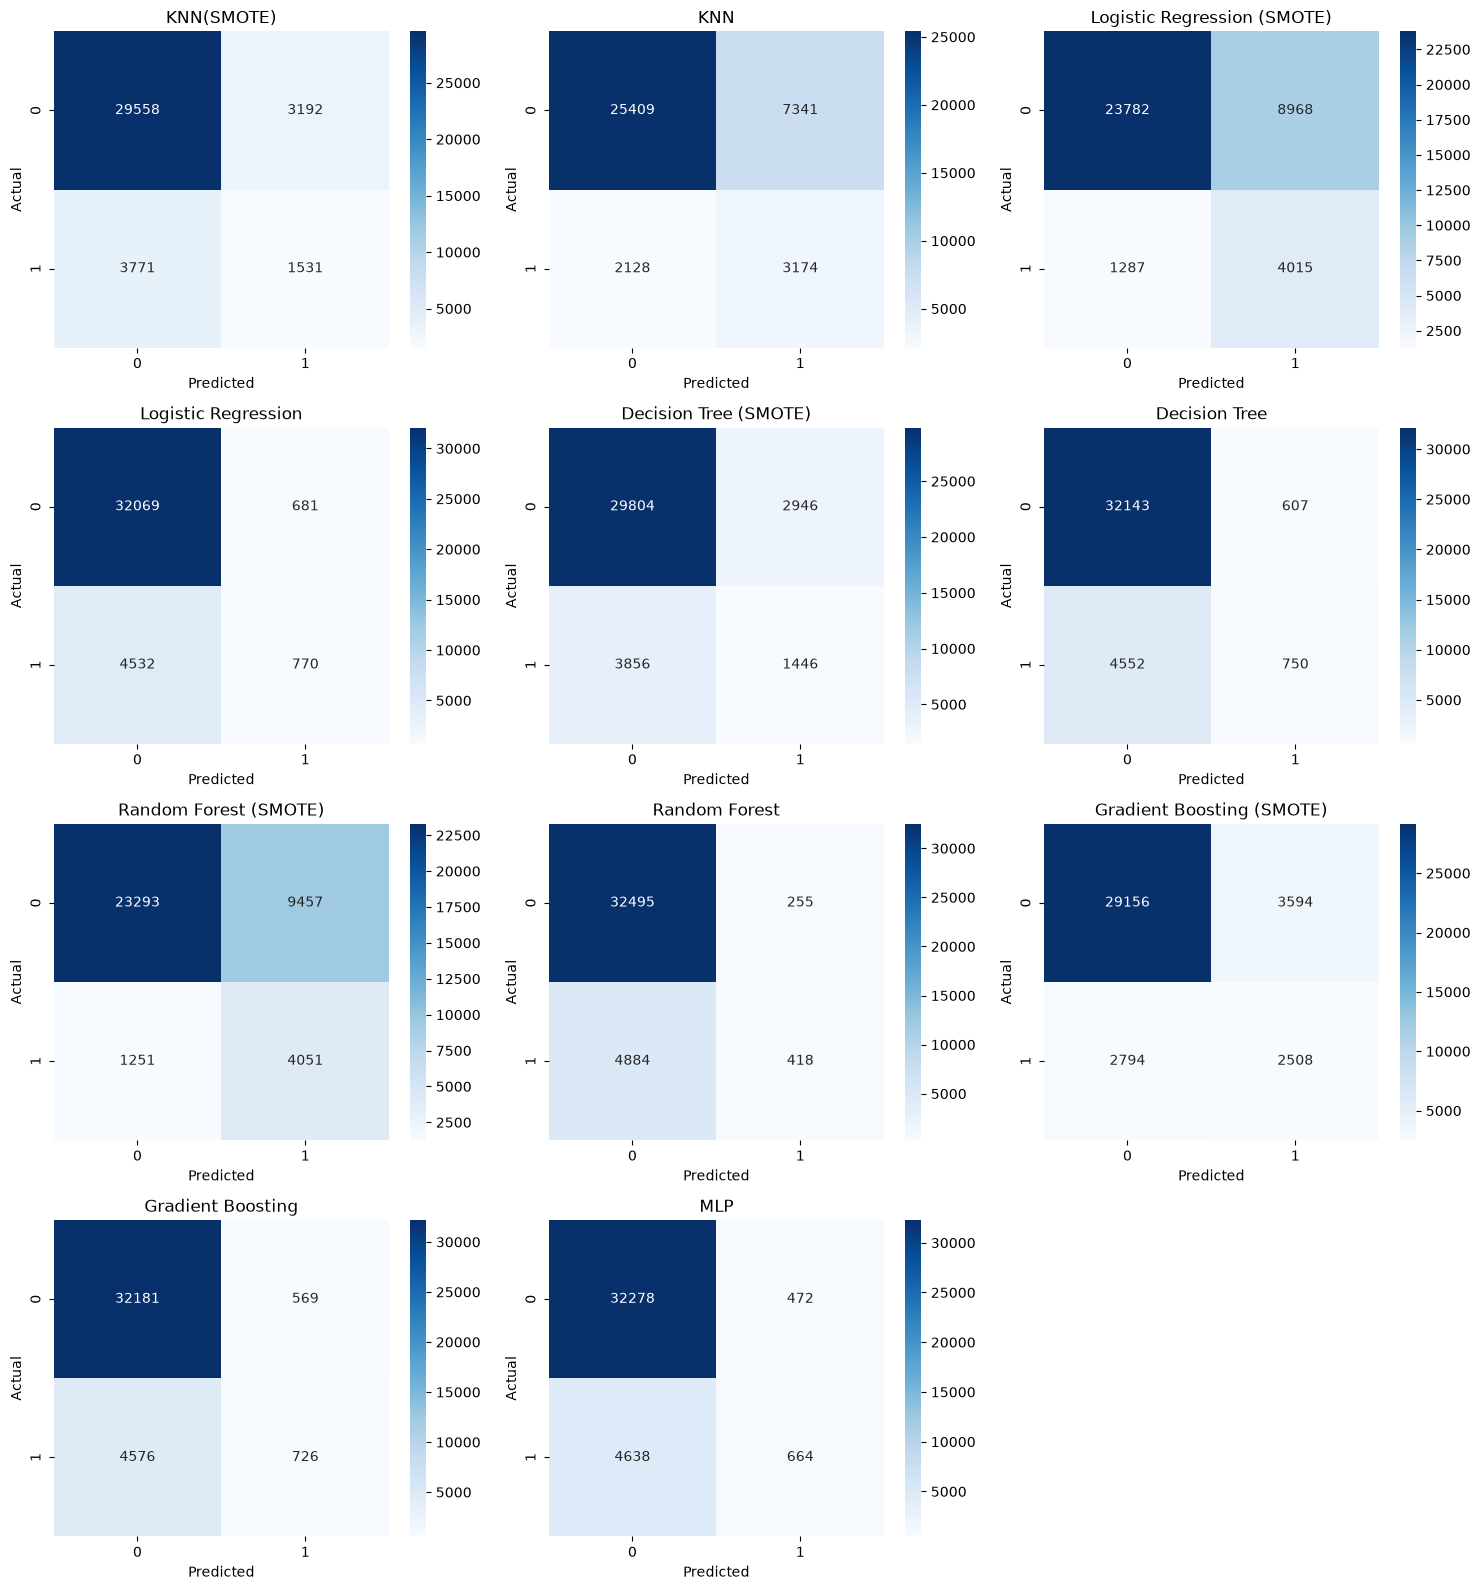

In [33]:
models = {
    "KNN(SMOTE)": knn_model,
    "KNN": knn_model_selected,
    "Logistic Regression (SMOTE)": lgs_model,
    "Logistic Regression": lgs_model_selected,
    "Decision Tree (SMOTE)": dt_model,
    "Decision Tree": dt_model_selected,
    "Random Forest (SMOTE)": rf_model,
    "Random Forest": rf_model_selected,
    "Gradient Boosting (SMOTE)": gb_model,
    "Gradient Boosting": gb_model_selected,
    "MLP": mlp_model_selected,
}

results = general.evaluate_models(
    models,
    X_test_selected,
    y_test
)

print(results)
general.plot_confusion_matrices(models,X_test_selected,y_test)

_**Comment**:_

The results show a clear trade-off between overall accuracy and the ability to detect positive diabetes cases. Models trained without SMOTE achieved the highest accuracy scores, reaching approximately 86.5% for MLP, Random Forest, Gradient Boosting, Decision Tree, and Logistic Regression. However, these models exhibited very low recall values, indicating that they failed to identify a large proportion of diabetic patients.

After applying SMOTE, recall increased substantially for most models. Logistic Regression and Random Forest achieved recall values above 75%, while Gradient Boosting attained the best balance between recall and precision. Although the overall accuracy decreased after oversampling, these models became significantly more effective at detecting positive diabetes cases.

This behavior is expected in imbalanced datasets. Without SMOTE, the models were biased toward the majority class and achieved high accuracy by correctly classifying non-diabetic individuals. With SMOTE, the classifiers learned more representative decision boundaries for the minority class, leading to improved detection of diabetic patients at the cost of additional false positives.

Among all evaluated models, Gradient Boosting combined with SMOTE achieved the highest F1-score (0.44). This indicates the best balance between precision and recall, making it the most suitable model when both correct diabetes detection and false positive reduction are important. Although Logistic Regression and Random Forest obtained higher recall values, they generated substantially more false positives, resulting in lower precision and comparable F1-scores.

In a healthcare context, recall is often more important than accuracy because failing to identify a diabetic patient may have more serious consequences than incorrectly flagging a healthy individual. Therefore, models trained with SMOTE may be preferable despite their lower accuracy, as they detect a significantly larger proportion of positive cases.

# **Conclusion**

The experiments demonstrate that relying solely on accuracy can be misleading when dealing with imbalanced medical datasets. While several models achieved accuracies above 86% without SMOTE, their recall values remained very low, indicating poor detection of diabetic patients. Applying SMOTE significantly improved recall across most classifiers by reducing the bias toward the majority class. Among all tested approaches, Gradient Boosting with SMOTE achieved the highest F1-score and the best balance between precision and recall, making it the most appropriate model for diabetes prediction.